# Saved research results — notebook v4.7.0

Code release **5.7.0**. Run from the repository root in the existing environment.
Ordinary execution evaluates the selected fixed expression and displays preserved diagnostic images.
It does not import PySR or start Julia. Test AUC is a selection score.


Expression_ID  train_auc  val_auc  test_auc  total_auc
   L2HL_1_050   0.957333 0.972696  0.961599   0.960129
        rows       auc
subset                
1        205  0.971951
2        205  0.993539
3        205  0.965805
4        205  0.953199
5        204  0.972164
6        204  0.974591
{'dataset': 'validation', 'rows': 1228, 'n_splits': 6, 'seed': 42, 'mean_subset_auc': 0.9718748846545884, 'sd_subset_auc': 0.013133522100882348, 'area_under_mean_roc': 0.9714520958083834}


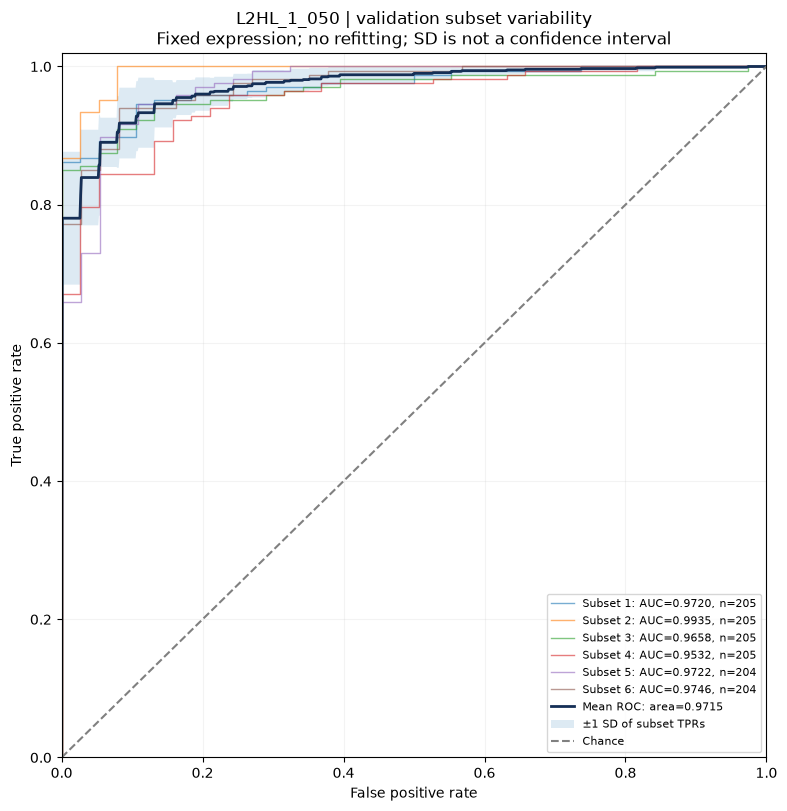

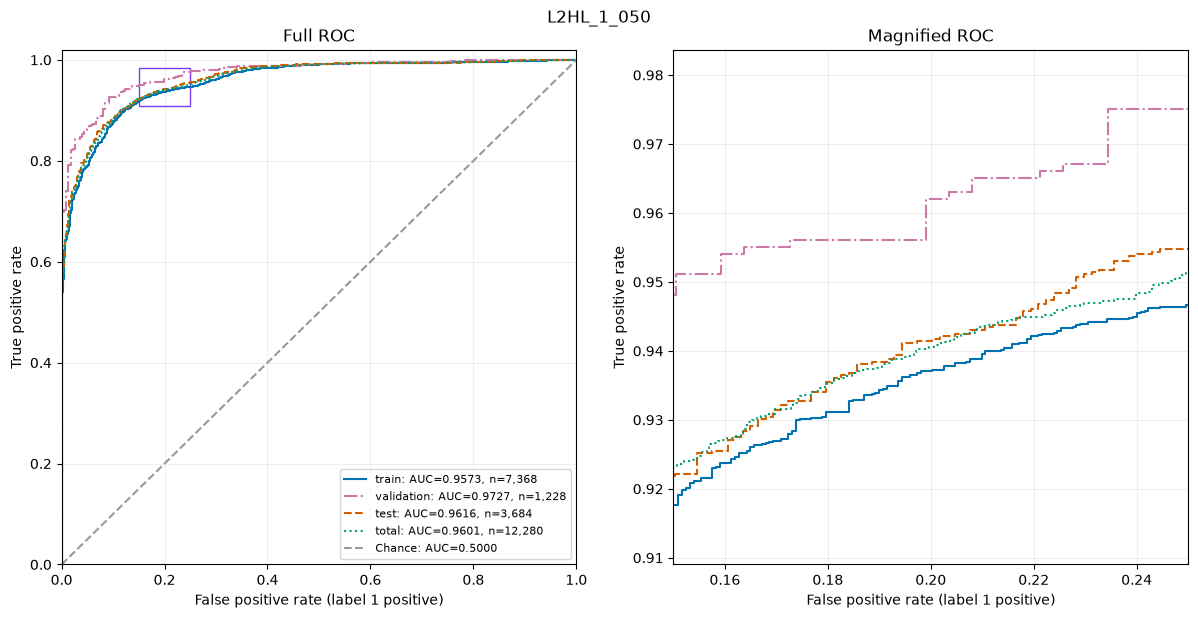

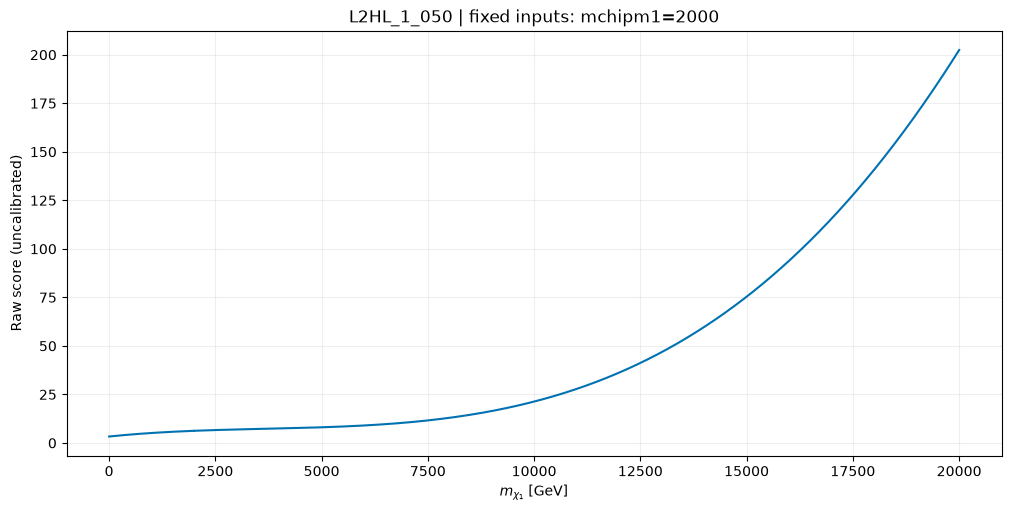

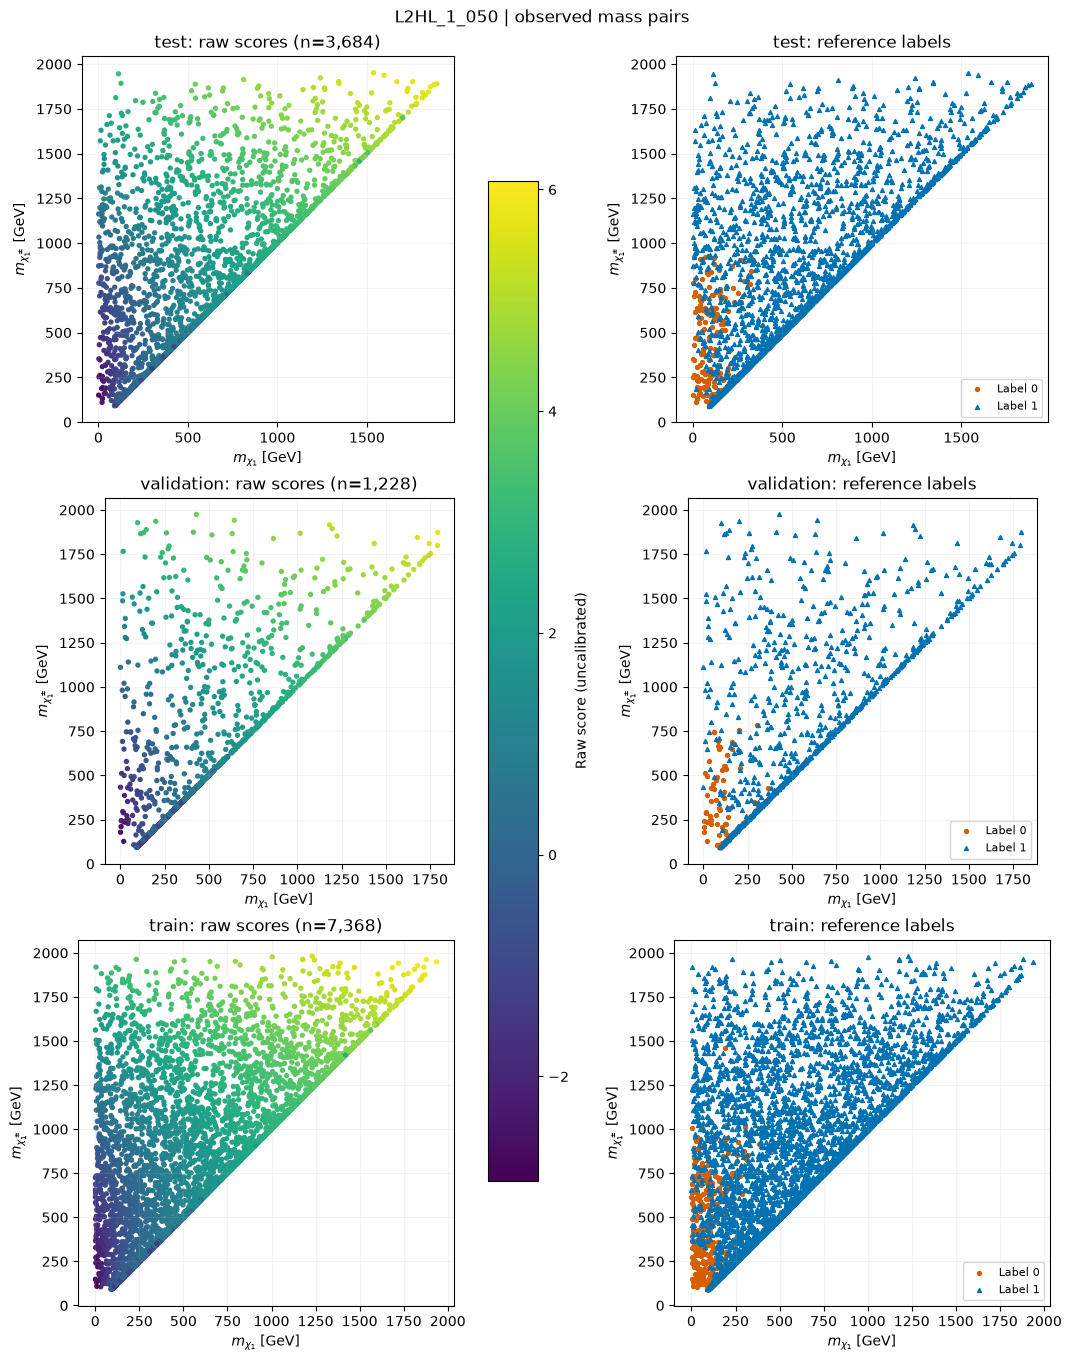

In [1]:
# Code release v5.7.0 · notebook artifact v4.7.0
from pathlib import Path
from plot_sr import main as inspect_saved_run

PROJECT_DIR = Path.cwd().resolve()
RUN_SOURCE = PROJECT_DIR / "results/L2HL_1_050/manifest.json"
EXPRESSION_ID = "L2HL_1_050"
DATA_CSV = PROJECT_DIR / "data/masses_exclusions.csv"
SAVE_PLOTS, SHOW_PLOTS = False, True

datasets, selected, evaluations = inspect_saved_run(
    RUN_SOURCE, EXPRESSION_ID, DATA_CSV,
    save_plots=SAVE_PLOTS, show_plots=SHOW_PLOTS,
)
X_train, y_train = datasets["train"]
X_val, y_val = datasets["validation"]


## Three different diagnostics

The four figures above use one fixed selected expression; the six validation subsets involve no refitting.
The two images below came from **eight fresh diagnostic fits per parent run**: four complexity limits
and four training fractions. Those models use PySR's own selection rule, separately from the parent's
test-AUC-selected expression. A single stochastic fit per point does not supply uncertainty estimates.

Original numeric curve arrays were not serialized. The curated manifests preserve the existing images,
eight child-run IDs per parent, and source hashes. New explicitly enabled fits save numeric tables and
lineage in a new ignored directory; they never replace these preserved images.

Hosted PNG/PDF files are optional ignored cache. Missing curve images produce links only; no automatic network access occurs. Run the explicit fetch command to cache them.


In [1]:
# Version v5.7.1 · fitting occurs only in an explicitly enabled call below.
def plot_pysr_curves(
    model, X_train, y_train, X_val, y_val, *, output_dir, parent_run_id,
    maxsizes=(10, 40, 70, 100), fractions=(0.25, 0.50, 0.75, 1.0), seed=42,
    data_csv=None,
):
    """Fit fresh diagnostic models and retain each child's inputs and scores.

    The seed controls training subsets, not a multithreaded symbolic search.
    Parent test-AUC winner selection is separate from candidate.predict().
    """
    from datetime import datetime, timezone
    import hashlib
    from pathlib import Path
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.base import clone
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import train_test_split
    from sklearn.utils.class_weight import compute_sample_weight
    from sr import _write_json_atomic

    for X, labels in ((X_train, y_train), (X_val, y_val)):
        if isinstance(labels, pd.Series) and hasattr(X, "index") and not X.index.equals(labels.index):
            raise ValueError("Feature and label indices must match before curve fitting.")

    y_train = np.asarray(y_train).reshape(-1)
    y_val = np.asarray(y_val).reshape(-1)
    if len(X_train) != len(y_train) or len(X_val) != len(y_val):
        raise ValueError("Feature rows and labels must match.")
    for labels in (y_train, y_val):
        if not np.array_equal(np.unique(labels), [0, 1]):
            raise ValueError("Both datasets must contain both labels: 0 and 1.")
    if (not maxsizes or len(set(maxsizes)) != len(maxsizes)
            or any(isinstance(size, bool) or int(size) != size or size < 1 for size in maxsizes)):
        raise ValueError("Complexity limits must be unique positive integers.")
    if not fractions or len(set(fractions)) != len(fractions) or any(not 0 < value <= 1 for value in fractions):
        raise ValueError("Training fractions must be unique and lie in (0, 1].")

    output_dir = Path(output_dir).resolve()
    output_dir.mkdir(parents=True, exist_ok=False)
    metadata = {
        "version": "0.1.0", "code_release": "5.7.0", "status": "running",
        "created_at_utc": datetime.now(timezone.utc).isoformat(), "parent_run_id": parent_run_id,
        "maxsizes": list(maxsizes), "fractions": list(fractions), "subset_seed": seed,
        "dataset_sha256": hashlib.sha256(Path(data_csv).read_bytes()).hexdigest() if data_csv else None,
        "model_selection": getattr(model, "model_selection", "best"),
        "interpretation": "Fresh diagnostic fits; not evaluation of one fixed parent winner.",
        "validation_row_ids": list(X_val.index) if hasattr(X_val, "index") else list(range(len(y_val))),
        "children": [],
    }
    manifest_path = output_dir / "curve_manifest.json"
    _write_json_atomic(manifest_path, metadata)
    rows = {"validation": [], "learning": []}

    def take_rows(X, indices):
        return X.iloc[indices] if hasattr(X, "iloc") else np.asarray(X)[indices]

    def fit_and_score(kind, value, indices, maxsize):
        child_id = f"{kind}_{len(metadata['children']) + 1}"
        X_sub, y_sub = take_rows(X_train, indices), y_train[indices]
        weights = compute_sample_weight("balanced", y_sub)
        candidate = clone(model).set_params(
            maxsize=maxsize, warm_start=False, run_id=child_id,
            output_directory=str(output_dir / "searches"),
        )
        child = {
            "run_id": child_id, "kind": kind, "x": value, "status": "running",
            "model_parameters": candidate.get_params(),
            "training_row_ids": list(X_sub.index) if hasattr(X_sub, "index") else indices.tolist(),
            "training_labels": (2 * y_sub.astype(float) - 1).tolist(),
            "sample_weights": weights.tolist(),
        }
        metadata["children"].append(child)
        _write_json_atomic(manifest_path, metadata)
        candidate.fit(X_sub, 2 * y_sub.astype(float) - 1, weights=weights)
        train_auc = float(roc_auc_score(y_sub, candidate.predict(X_sub)))
        val_auc = float(roc_auc_score(y_val, candidate.predict(X_val)))
        best = candidate.get_best()
        child.update(status="complete", train_auc=train_auc, validation_auc=val_auc,
                     selected_expression_id=f"{child_id}_0{int(best['complexity'])}",
                     selected_expression={key: best[key] for key in ("complexity", "loss", "equation")})
        rows[kind].append((value, train_auc, val_auc))
        _write_json_atomic(manifest_path, metadata)
        pd.DataFrame(rows[kind], columns=["x", "train_auc", "validation_auc"]).to_csv(
            output_dir / f"{kind}.csv", index=False)

    try:
        indices = np.arange(len(y_train))
        for size in maxsizes:
            fit_and_score("validation", size, indices, size)
        for fraction in fractions:
            subset = indices
            if fraction < 1:
                subset, _ = train_test_split(indices, train_size=fraction, stratify=y_train, random_state=seed)
            fit_and_score("learning", len(subset), subset, model.maxsize)
        arrays = {kind: np.asarray(values) for kind, values in rows.items()}
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, kind, xlabel in zip(axes, ("validation", "learning"),
                                    ("Maximum equation complexity (maxsize)", "Training samples")):
            values = arrays[kind]
            ax.plot(values[:, 0], values[:, 1], "o-", label="Train")
            ax.plot(values[:, 0], values[:, 2], "o-", label="Validation")
            ax.axhline(.5, color="gray", linestyle=":", label="Chance AUC")
            ax.set(title=f"{kind.capitalize()} curve", xlabel=xlabel, ylabel="ROC-AUC", ylim=(0, 1.02))
            ax.grid(alpha=.25)
            ax.legend()
        fig.tight_layout()
        fig.savefig(output_dir / "valid-learn-curve.png", dpi=150)
        metadata["status"] = "complete"
        _write_json_atomic(manifest_path, metadata)
        return fig, arrays
    except Exception as error:
        if metadata["children"] and metadata["children"][-1]["status"] == "running":
            metadata["children"][-1]["status"] = "failed"
        metadata.update(status="failed", error={"type": type(error).__name__, "message": str(error)})
        _write_json_atomic(manifest_path, metadata)
        raise


Attempting to load model from /Users/vaheedgorgeen/libs/train-symexpr-bsm/output/L2HL_1/checkpoint.pkl...
[ Info: Started!
[ Info: Final population:
[ Info: Results saved to:


───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.000e+00  0.000e+00  y = 6.0247e-10
3           8.666e-01  7.159e-02  y = mchi1 * 0.00073089
4           7.765e-01  1.098e-01  y = cube(mchi1 * 0.0015307)
5           6.241e-01  2.185e-01  y = (mchi1 * 0.00295) + -0.95983
6           6.191e-01  8.014e-03  y = square(mchi1 * 0.0021786) + -0.64931
7           5.441e-01  1.292e-01  y = ((mchi1 * mchipm1) * 4.991e-06) + -0.77957
9           5.400e-01  3.800e-03  y = ((mchipm1 * 0.0014018) - (mchi1 * -0.002067)) + -1.329...
                                      9
10          5.328e-01  1.349e-02  y = square((mchipm1 * 0.00080957) - (mchi1 * -0.001532)) +...
                                       -0.89125
───────────────────────────────────────────────────────────────────────────────────────────────────
  - /Users/vaheedgorgeen/libs/train-symexpr-bsm/output/curve_diagnostics/L2HL_1/202610

/Users/vaheedgorgeen/libs/train-symexpr-bsm/.venv/lib/python3.13/site-packages/pysr/sr.py:1971: UserWarning: Note: Using a large maxsize for the equation search will be exponentially slower and use significant memory.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 2.160e+04
Progress: 72 / 100 total iterations (72.250%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.000e+00  0.000e+00  y = -3.6384e-09
3           8.666e-01  7.158e-02  y = mchi1 * 0.0007238
4           7.765e-01  1.097e-01  y = cube(mchi1 * 0.0015401)
5           6.241e-01  2.185e-01  y = (mchi1 * 0.002764) + -0.93217
6           6.239e-01  3.051e-04  y = (square(mchi1) * 5.4359e-06) + -0.75123
7           5.482e-01  1.295e-01  y = ((mchi1 + mchipm1) * 0.001466) + -1.1687
8           5.441e-01  7.386e-03  y = square((mchi1 + mchipm1) * -0.0010198) + -0.78298
9           5.367e-01  1.371e-02  y = (((mchipm1 + mchi1) + mchi1) * 0.001074) + -1.197
10          5.316e-01  9.571e-03  y = square(((mchi1 + mchipm1) + mchi1) * -0.00073213) + -0...


[ Info: Final population:
[ Info: Results saved to:


...

───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.000e+00  0.000e+00  y = 2.146e-10
3           8.695e-01  6.993e-02  y = mchipm1 * 0.0005008
4           7.877e-01  9.883e-02  y = cube(mchi1 * 0.0013029)
5           6.297e-01  2.239e-01  y = (mchi1 * 0.0028525) + -0.99847
6           6.247e-01  7.974e-03  y = square(mchi1 * 0.0021007) + -0.64536
7           5.451e-01  1.363e-01  y = (mchi1 * (mchipm1 * 5.0477e-06)) + -0.80056
9           5.391e-01  5.471e-03  y = ((mchi1 + (mchipm1 + mchi1)) * 0.00097851) + -1.1666
13          5.330e-01  2.834e-03  y = (((mchi1 + mchipm1) * ((mchipm1 + mchi1) + mchi1)) * 7...
                                      .0952e-07) + -0.79265
15          5.330e-01  2.212e-11  y = (((mchi1 + mchipm1) * ((mchi1 + (mchi1 + 7.0952e-07)) ...
                                      + mchipm1)) * 7.0952e-07) + -0.79265
17          5.330e-01  6.405e-06  y = ((((mch

/Users/vaheedgorgeen/libs/train-symexpr-bsm/.venv/lib/python3.13/site-packages/pysr/sr.py:1971: UserWarning: Note: Using a large maxsize for the equation search will be exponentially slower and use significant memory.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 4.660e+03
Progress: 9 / 100 total iterations (9.500%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.000e+00  0.000e+00  y = 2.8514e-08
3           8.667e-01  7.155e-02  y = mchi1 * 0.00074838
5           7.049e-01  1.033e-01  y = (-249.22 / mchipm1) + 0.83802
7           6.540e-01  3.749e-02  y = (-565.68 / (mchi1 + mchipm1)) + 0.98451
9           6.046e-01  3.928e-02  y = square(mchi1 * square(mchipm1 * 7.1468e-05)) + -0.5515...
                                      6
17          5.978e-01  1.408e-03  y = square((mchi1 + (((mchi1 + mchi1) + mchi1) + mchi1)) *...
                                       square(mchipm1 * 3.2908e-05)) + -0.46439
19          5.785e-01  1.635e-02  y = (((mchi1 + mchi1) + ((mchi1 + (square(mchipm1) * 3.290...
       

[ Info: Final population:
[ Info: Results saved to:


───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.000e+00  0.000e+00  y = 2.6232e-10
3           8.667e-01  7.155e-02  y = mchi1 * 0.00074838
4           8.006e-01  7.928e-02  y = square(mchi1) * 1.448e-06
5           6.246e-01  2.483e-01  y = (mchi1 * 0.0027311) - 0.89474
6           6.223e-01  3.584e-03  y = square(mchi1 * -0.0021327) - 0.68374
7           5.513e-01  1.211e-01  y = ((mchi1 + mchipm1) * 0.0014866) - 1.2587
8           5.466e-01  8.600e-03  y = square((mchipm1 + mchi1) * 0.00096728) - 0.76018
9           5.420e-01  8.566e-03  y = (((mchi1 * -2.131) - mchipm1) * -0.00096024) + -1.1943
11          5.364e-01  5.140e-03  y = (((1.4748 - mchi1) - (mchi1 + mchipm1)) * -0.0010933) ...
                                      - 1.2206
12          5.364e-01  2.649e-05  y = cube(((0.71965 - (mchipm1 + mchi1)) - mchi1) * -0.0007...
                                      2098) - 

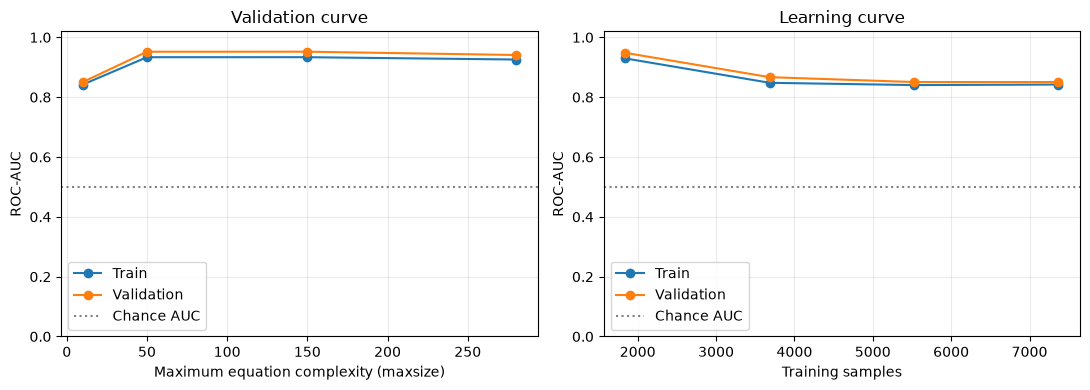

In [12]:
# This switch authorizes new searches. Keep False for ordinary saved-result inspection.
RUN_CURVE_FITS = True
# The target expressions you want to check
CURVE_EXPRESSIONS = ["L2HL_1_050"]

if RUN_CURVE_FITS:
    from datetime import datetime, timezone
    import uuid
    import matplotlib.pyplot as plt
    from pysr import PySRRegressor

    for expression_id in CURVE_EXPRESSIONS:
        parent_run_id = expression_id.rsplit("_", 1)[0]
        model = PySRRegressor.from_file(run_directory=PROJECT_DIR / "output" / parent_run_id)
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8]
        destination = PROJECT_DIR / "output/curve_diagnostics" / parent_run_id / stamp
        fig, curve_results = plot_pysr_curves(
            model, X_train, y_train, X_val, y_val,
            output_dir=destination, parent_run_id=parent_run_id, data_csv=DATA_CSV,
            maxsizes=(10,50,150,280)
        )
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)
else:
    from IPython.display import Image, Markdown, display
    from fetch_artifacts import cached_artifact, artifact_url

    for expression_id in CURVE_EXPRESSIONS:
        print(f"{expression_id}: saved refitted-model diagnostics; historical numerical tables unavailable.")
        cached = cached_artifact(expression_id, "valid-learn-curve.png", project_dir=PROJECT_DIR)
        if cached is not None:
            display(Image(filename=str(cached)))
        else:
            url = artifact_url(expression_id, "valid-learn-curve.png")
            display(Markdown(f"[View the preserved {expression_id} curve image]({url})"))
            print(f"Optional cache: .venv/bin/python fetch_artifacts.py --expression {expression_id}")
